# Diagonal Gibbs preparation: purification, a mixed state, and samples

The two-qubit model is $H/E_0=0.6 Z_0Z_1+0.35 Z_0-0.2 Z_1$, in the chosen energy unit $E_0=1$, with $k_B=1$. At inverse temperature $\beta=1.25/E_0$, $T=0.8E_0$. We explicitly enumerate its diagonal energies, normalize Boltzmann weights and load amplitudes with primitive controlled rotations.

The circuit is an original bounded implementation, not a scalable Gibbs filtering algorithm. Classical coefficient and rotation loading costs grow exponentially. Qiskit 2.6.2 supplies the circuit/density tools; SciPy 1.18.1 supplies an independent matrix-exponential reference. The chapter cites the exact sources and primary algorithm context.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import DensityMatrix, partial_trace

root = Path.cwd()
if not (root / "src/openquantum/simulation/gibbs.py").exists() and (root.parent / "src/openquantum/simulation/gibbs.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/gibbs.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import gibbs
else:
    # Save gibbs.py beside the downloaded notebook.
    sys.path.insert(0, str(root))
    import gibbs

energies = gibbs.diagonal_ising_energies()
beta = 1.25
probabilities = gibbs.gibbs_probabilities(energies, beta)
display(pd.DataFrame({"bitstring q1q0": [f"{x:02b}" for x in range(4)], "energy": energies, "Boltzmann probability": probabilities}))

,bitstring q1q0,energy,Boltzmann probability
0,00,0.75,0.062797
1,01,-1.15,0.675133
2,10,-0.05,0.170700
3,11,0.45,0.091369


## Explicit purification circuit

Starting from zero system and reference wires, the loader prepares $\sum_x\sqrt{p_x}|x\rangle_S$, then system-to-reference CX gates produce $\sum_x\sqrt{p_x}|x\rangle_S|x\rangle_R$. System wires are q0,q1 and reference wires q2,q3. The reduced system is Gibbs only after tracing out or resetting the reference without conditioning. Uncomputing the CX gates would restore a coherent amplitude state instead.

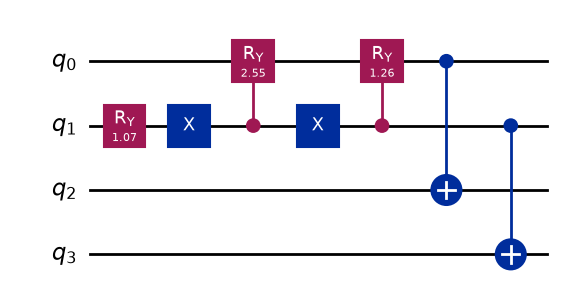

In [2]:
gibbs.diagonal_gibbs_purification(energies, beta).draw(output="mpl", fold=30)

## Reduced state and independent classical answer

For several inverse temperatures, the actual quantum circuit's reduced density operator is compared with normalized $e^{-\beta H}$ from a separate matrix exponential. Trace distance, trace, positivity and diagonal means are distinct checks. The reference is never used as a circuit gate.

In [3]:
checks = [gibbs.gibbs_check(energies, value) for value in (0, .25, 1.25, 5)]
rows = [{"beta": c["beta"], "trace distance": c["trace_distance"], "trace": c["trace_real"], "minimum eigenvalue": c["minimum_eigenvalue"], **c["actual_observables"]} for c in checks]
display(pd.DataFrame(rows))
assert max(c["trace_distance"] for c in checks) < 1e-11
mixed_circuit = gibbs.build_gibbs_mixed_preparation(energies, beta)
actual_mixed = partial_trace(DensityMatrix.from_instruction(mixed_circuit), [2, 3]).data
np.testing.assert_allclose(actual_mixed, gibbs.exact_diagonal_gibbs(energies, beta), atol=1e-12)
print("Explicit reference-reset schedule leaves a retained thermal system.")

,beta,trace distance,trace,minimum eigenvalue,energy,Z0,Z1,Z0Z1
0,0.00,1.110223e-16,1.0,0.250000,5.551115e-17,2.220446e-16,2.220446e-16,0.000000
1,0.25,6.938894e-17,1.0,0.203778,-1.375988e-01,-9.465398e-02,6.291183e-02,-0.153146
2,1.25,9.714451e-17,1.0,0.062797,-6.967240e-01,-5.330049e-01,4.758606e-01,-0.691667
3,5.00,1.123233e-16,1.0,0.000075,-1.144849e+00,-9.917140e-01,9.911951e-01,-0.999183


Explicit reference-reset schedule leaves a retained thermal system.


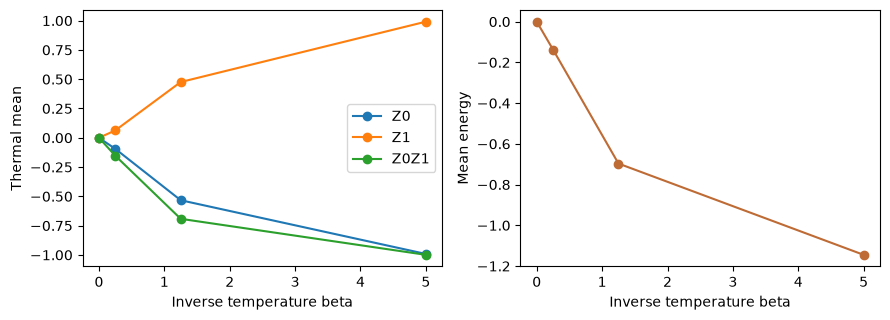

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for key in ("Z0", "Z1", "Z0Z1"):
    axes[0].plot([r["beta"] for r in rows], [r[key] for r in rows], "o-", label=key)
axes[0].set(xlabel="Inverse temperature beta", ylabel="Thermal mean")
axes[0].legend()
axes[1].plot([r["beta"] for r in rows], [r["energy"] for r in rows], "o-", color="#be6b35")
axes[1].set(xlabel="Inverse temperature beta", ylabel="Mean energy")
fig.tight_layout()
plt.show()

## Three output contracts and one-mean shot budgets

The purification circuit leaves system and reference unmeasured. The mixed-state preparation schedule initializes all four wires and irreversibly resets the two reference wires, leaving the system unmeasured. The measured trial initializes all four wires, purifies, measures only the two system wires and discards the reference without conditioning.

Every trial succeeds ideally with probability one; there is no postselection, overlap assumption or amplification. Arbitrary rotations still need coherent synthesis. Physical reset/discard/readout time and error correction are unavailable. For one fixed iid scalar mean, Hoeffding gives a separate shot count. Measuring the diagonal energy uses its full outcome range; simultaneous confidence for several reported means requires a new allocation.

In [5]:
purification = gibbs.decompose_gibbs(gibbs.diagonal_gibbs_purification(energies, beta))
mixed = gibbs.decompose_gibbs(gibbs.build_gibbs_mixed_preparation(energies, beta))
trial = gibbs.decompose_gibbs(gibbs.build_gibbs_trial(energies, beta))
display(pd.DataFrame({"purification": dict(purification.count_ops()), "retained mixed state": dict(mixed.count_ops()), "measured trial": dict(trial.count_ops())}).fillna(0).astype(int))
shots_z = gibbs.bounded_mean_shots(.03, .005)
shots_energy = gibbs.bounded_mean_shots(.03, .005, energies.min(), energies.max())
print(f"One Z0 mean: {shots_z} iid trials; one energy mean: {shots_energy} iid trials.")
print("These are separate unexecuted statistical proposals; synthesis and physical faults are separate.")

,purification,retained mixed state,measured trial
cx,6,6,6
ry,5,5,5
x,2,2,2
reset,0,6,4
measure,0,0,2


One Z0 mean: 13315 iid trials; one energy mean: 12017 iid trials.
These are separate unexecuted statistical proposals; synthesis and physical faults are separate.


## Optional live temperature exploration

Kernel-backed controls are omitted from static builds. The saved outputs above run without a widget kernel. This explorer computes the actual reduced circuit state, not a hardcoded thermal-state object.

In [6]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(beta=1.25):
        result = gibbs.gibbs_check(energies, beta)
        display(pd.DataFrame([{"beta": beta, "trace distance": result["trace_distance"], **result["actual_observables"]}]))
    display(widgets.interactive(explore, beta=widgets.FloatSlider(min=0, max=5, step=.25, value=1.25)))

## Scale and precision limits

Explicit coefficient loading permits at most eight system qubits (and eight reference qubits), while dense circuit/reference validation stops at six system qubits. The product of inverse temperature and energy range is at most 700, keeping the declared floating weight-loading domain explicit. Circuit generation does not demonstrate an efficient large-system Gibbs algorithm. General Hamiltonians, scalable filtering/mixing, certified rotation synthesis and physical-resource estimates remain planned.